In [ ]:
'''Для выполнения задания используется датасет из предыдущей промежуточной аттестации, связанной с анализом оттока клиентов банка.
Данные содержат информацию о клиентах, их банковских продуктах и транзакционной активности.
На основе этих данных буду обучать модели машинного обучения для определения вероятности оттока клиента.'''

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

Saving customer_churn_features.csv to customer_churn_features.csv


In [2]:
df = pd.read_csv("customer_churn_features.csv")

print("Размер датасета:", df.shape)

display(df.head())

print("\nИнформация о данных:")
df.info()

Размер датасета: (10000, 22)


,customer_id,age,gender,registration_date,annual_income,account_count,active_account_count,card_count,active_card_count,transaction_count,...,card_purchase_count,atm_withdrawal_count,transfer_out_count,utility_payment_count,transfer_count,loan_count,total_loan_amount,avg_interest_rate,last_transaction_date,churn
0,1,34,M,2025-07-12,455276.04,1,1,1,1,266,...,249,5,0,0,0,0,0.0,0.0,2026-01-27,0
1,2,54,M,2025-03-22,1945830.96,2,2,1,1,465,...,434,9,0,4,0,0,0.0,0.0,2026-01-26,0
2,3,18,F,2025-10-01,315794.16,1,1,1,1,155,...,144,2,1,1,1,0,0.0,0.0,2026-01-27,0
3,4,18,F,2025-11-22,647645.88,2,2,1,1,76,...,70,2,0,2,0,0,0.0,0.0,2026-01-25,0
4,5,49,M,2025-09-30,1061109.84,2,2,0,0,165,...,153,2,0,3,0,0,0.0,0.0,2026-01-27,0



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   age                       10000 non-null  int64  
 2   gender                    10000 non-null  object 
 3   registration_date         10000 non-null  object 
 4   annual_income             10000 non-null  float64
 5   account_count             10000 non-null  int64  
 6   active_account_count      10000 non-null  int64  
 7   card_count                10000 non-null  int64  
 8   active_card_count         10000 non-null  int64  
 9   transaction_count         10000 non-null  int64  
 10  total_transaction_amount  10000 non-null  float64
 11  avg_transaction_amount    10000 non-null  float64
 12  card_purchase_count       10000 non-null  int64  
 13  atm_withdrawal_count      10000 non-null

In [ ]:
'''В качестве целевой переменной я выбрала churn, которая показывает, ушел клиент из банка или нет.
Это задача бинарной классификации, поскольку целевая переменная принимает два значения: 0 и 1.
Для обучения моделей я выбрала несколько признаков, которые могут влиять на отток: возраст клиента,
годовой доход, количество счетов и карт, транзакционная активность, наличие кредитов и общая сумма кредитов.

Идентификатор клиента и даты я не использую, поскольку они не характеризуют непосредственно поведение клиента.'''

In [3]:
# Целевая переменная
y = df["churn"]

# Объясняющие признаки
features = [
    "age",
    "annual_income",
    "account_count",
    "active_account_count",
    "card_count",
    "active_card_count",
    "transaction_count",
    "avg_transaction_amount",
    "card_purchase_count",
    "atm_withdrawal_count",
    "transfer_out_count",
    "utility_payment_count",
    "loan_count",
    "total_loan_amount",
    "avg_interest_rate"
]

X = df[features].copy()

print("Количество признаков:", len(features))
print("\nРаспределение целевой переменной:")
print(y.value_counts())

print("\nДоля каждого класса, %:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nРазмер X:", X.shape)
print("Размер y:", y.shape)

Количество признаков: 15

Распределение целевой переменной:
churn
0    9303
1     697
Name: count, dtype: int64

Доля каждого класса, %:
churn
0    93.03
1     6.97
Name: proportion, dtype: float64

Размер X: (10000, 15)
Размер y: (10000,)


In [ ]:
'''у нас здесь наблюдается дисбаланс классов — клиентов без оттока 93,03%, а с оттоком только 6,97%.
Поэтому при оценке моделей будем обращать особое внимание на Recall, Precision и F1-score, а не только на Accuracy.'''

In [ ]:
'''Я разделила исходный датасет на две части: обучающую (80%) и тестовую (20%).
Обучающая выборка будет использоваться для настройки и обучения моделей, а тестовая —
для проверки качества их предсказаний на данных, которые модели ранее не видели.
Для сохранения исходного соотношения классов я использую параметр stratify=y.'''

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nРаспределение классов в обучающей выборке:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nРаспределение классов в тестовой выборке:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Размер обучающей выборки: (8000, 15)
Размер тестовой выборки: (2000, 15)

Распределение классов в обучающей выборке:
churn
0    93.02
1     6.98
Name: proportion, dtype: float64

Распределение классов в тестовой выборке:
churn
0    93.05
1     6.95
Name: proportion, dtype: float64


In [ ]:
'''Сначала я подготовила данные для алгоритма SVM. Поскольку метод опорных векторов чувствителен к масштабу признаков,
я использую стандартизацию с помощью StandardScaler.

Стандартизация приводит признаки к сопоставимому масштабу. Это особенно важно, поскольку в датасете присутствуют показатели
с разными единицами измерения, например возраст, доход и количество транзакций.
Стандартизацию я буду выполнять внутри пайплайна, чтобы избежать утечки данных из тестовой выборки.'''

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Создание Pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(class_weight="balanced"))
])

print("Pipeline для SVM создан.")

Pipeline для SVM создан.


In [7]:
# Ускоренный подбор параметров SVM
param_grid_svm = {
    "svm__kernel": ["linear", "rbf"],
    "svm__C": [0.1, 1],
    "svm__gamma": ["scale"]
}

grid_svm = GridSearchCV(
    svm_pipeline,
    param_grid_svm,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_svm.fit(X_train, y_train)

print("Лучшие параметры:", grid_svm.best_params_)
print("Лучший F1-score:", round(grid_svm.best_score_, 3))

best_svm = grid_svm.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Лучшие параметры: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Лучший F1-score: 0.11


In [ ]:
'''Теперь я проверю, как модель работает на тестовой выборке, и выведу основные метрики качества.'''

In [8]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Делаю прогноз на тестовой выборке
y_pred_svm = best_svm.predict(X_test)

# Вывожу матрицу ошибок
print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred_svm))

# Вывожу основные метрики
print("\nОтчет о качестве модели:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Нет оттока", "Отток"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 3))
print("Precision:", round(precision_score(y_test, y_pred_svm, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred_svm, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred_svm, zero_division=0), 3))

Матрица ошибок:
[[995 866]
 [ 82  57]]

Отчет о качестве модели:
              precision    recall  f1-score   support

  Нет оттока       0.92      0.53      0.68      1861
       Отток       0.06      0.41      0.11       139

    accuracy                           0.53      2000
   macro avg       0.49      0.47      0.39      2000
weighted avg       0.86      0.53      0.64      2000

Accuracy: 0.526
Precision: 0.062
Recall: 0.41
F1-score: 0.107


In [ ]:
'''Результат показывает, что модель находит 41% клиентов с оттоком, но при этом часто ошибочно
относит к ним клиентов без оттока. Точность определения класса «Отток» составляет всего 6,2%.
Это говорит о том, что качество модели пока невысокое.

Теперь я построю график с разделяющей границей SVM. Так как основная модель использует
15 признаков, для наглядного двумерного графика я отдельно возьму два признака:
количество транзакций и среднюю сумму транзакции. Это будет иллюстрация работы SVM, а не график полной модели.'''

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


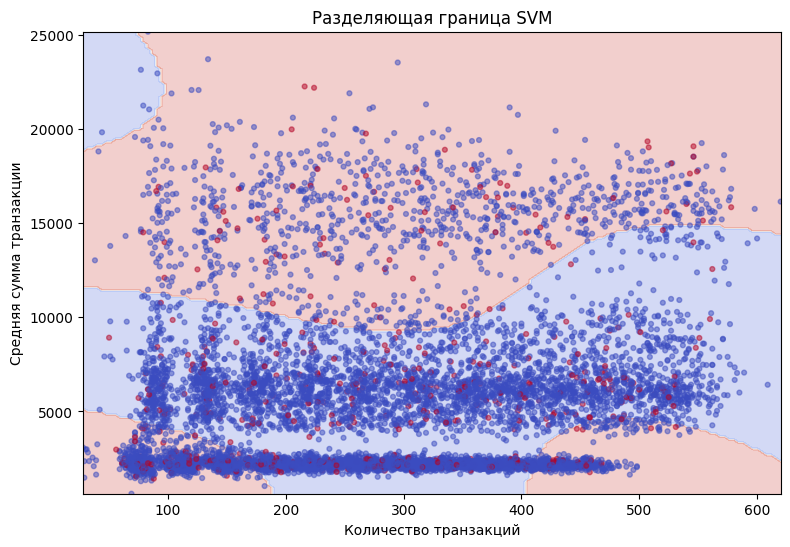

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Выбираю два признака для визуализации
features_2d = ["transaction_count", "avg_transaction_amount"]

X_train_2d = X_train[features_2d]
y_train_2d = y_train

# Обучаю отдельную модель SVM на двух признаках
svm_2d = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=0.1, class_weight="balanced")
)
svm_2d.fit(X_train_2d, y_train_2d)

# Создаю сетку точек для построения границы
x_min, x_max = X_train_2d.iloc[:, 0].min(), X_train_2d.iloc[:, 0].max()
y_min, y_max = X_train_2d.iloc[:, 1].min(), X_train_2d.iloc[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm_2d.predict(grid).reshape(xx.shape)

# Строю график
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
plt.scatter(
    X_train_2d.iloc[:, 0],
    X_train_2d.iloc[:, 1],
    c=y_train_2d,
    cmap="coolwarm",
    s=12,
    alpha=0.5
)

plt.xlabel("Количество транзакций")
plt.ylabel("Средняя сумма транзакции")
plt.title("Разделяющая граница SVM")
plt.show()

In [ ]:
'''Я перехожу к обучению дерева решений. В отличие от SVM, этому алгоритму не требуется стандартизация признаков.
Для подбора параметров я использую GridSearchCV и метрику F1-score, чтобы учитывать качество определения клиентов с оттоком.'''

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Создаю модель дерева решений
tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Задаю параметры для подбора
param_grid_tree = {
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5],
    "criterion": ["gini", "entropy"]
}

# Подбираю лучшие параметры
grid_tree = GridSearchCV(
    tree_model,
    param_grid_tree,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_tree.fit(X_train, y_train)

print("Лучшие параметры:", grid_tree.best_params_)
print("Лучший F1-score:", round(grid_tree.best_score_, 3))

best_tree = grid_tree.best_estimator_

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Лучшие параметры: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 5, 'min_samples_split': 2}
Лучший F1-score: 0.127


In [ ]:
'''Теперь я проверю качество дерева решений на тестовой выборке с помощью матрицы ошибок и основных метрик.'''

In [11]:
# Делаю прогноз на тестовой выборке
y_pred_tree = best_tree.predict(X_test)

# Вывожу матрицу ошибок
print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred_tree))

# Вывожу отчет о качестве модели
print("\nОтчет о качестве модели:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["Нет оттока", "Отток"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, y_pred_tree), 3))
print("Precision:", round(precision_score(y_test, y_pred_tree, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred_tree, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred_tree, zero_division=0), 3))

Матрица ошибок:
[[870 991]
 [ 75  64]]

Отчет о качестве модели:
              precision    recall  f1-score   support

  Нет оттока       0.92      0.47      0.62      1861
       Отток       0.06      0.46      0.11       139

    accuracy                           0.47      2000
   macro avg       0.49      0.46      0.36      2000
weighted avg       0.86      0.47      0.58      2000

Accuracy: 0.467
Precision: 0.061
Recall: 0.46
F1-score: 0.107


In [ ]:
'''Результат дерева решений очень близок к результату SVM. Дерево находит 46% клиентов с оттоком,
но точность таких прогнозов составляет только 6,1%. F1-score на тестовой выборке равен 0.107.

Теперь я построю визуализацию дерева решений. Чтобы схема была читаемой, покажу первые три уровня дерева.

Я визуализирую дерево решений, чтобы посмотреть, по каким признакам модель разделяет клиентов на группы.
Для удобства отображения ограничу глубину схемы тремя уровнями, хотя сама модель обучена с глубиной 7.'''

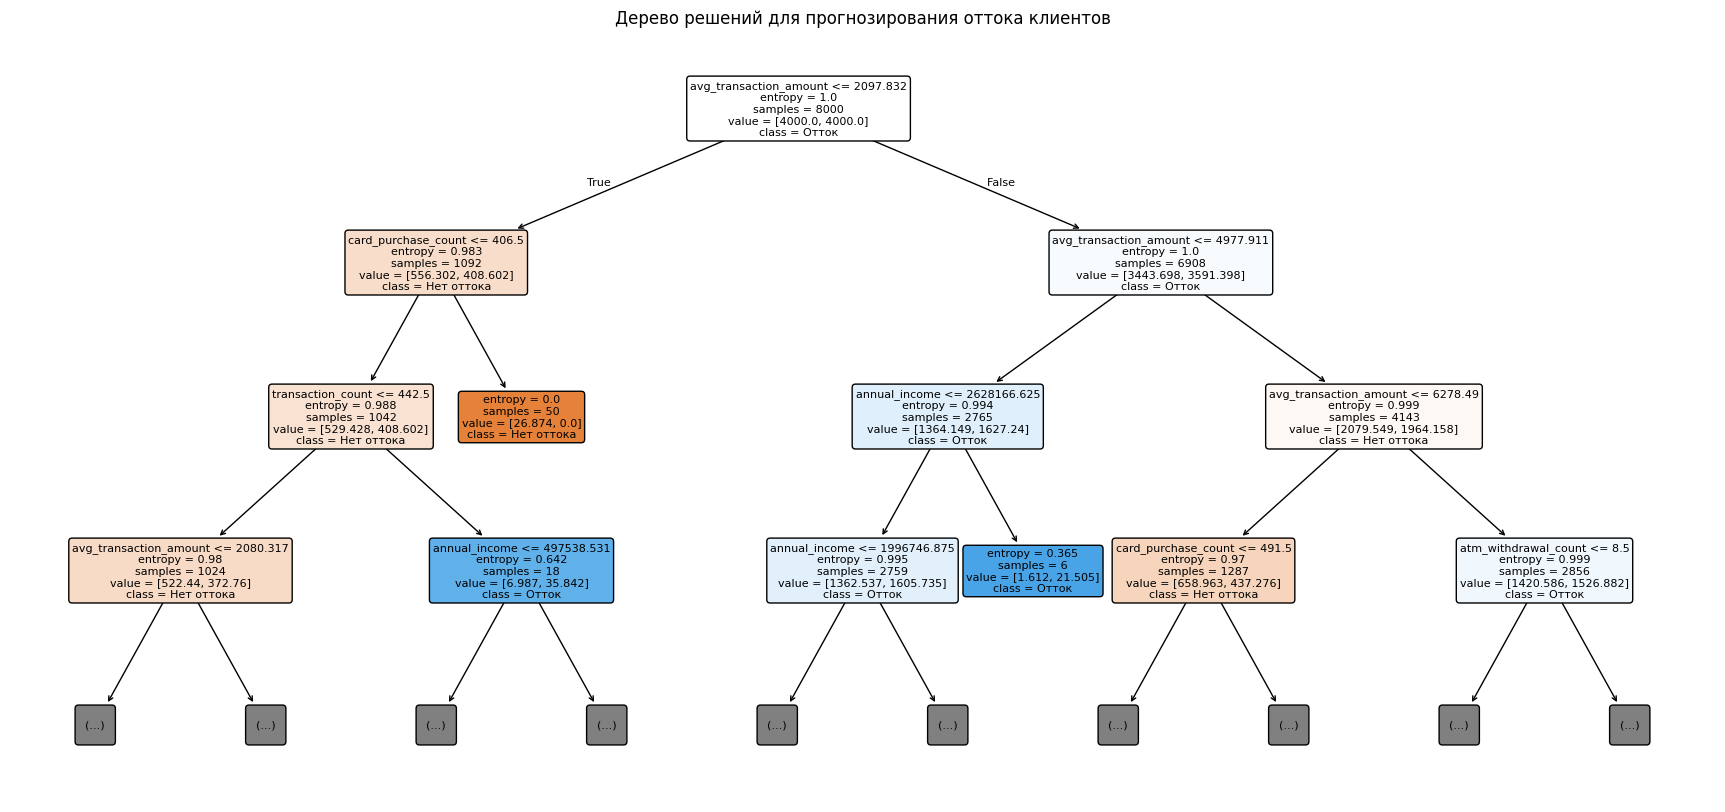

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    best_tree,
    feature_names=features,
    class_names=["Нет оттока", "Отток"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Дерево решений для прогнозирования оттока клиентов")
plt.show()

In [ ]:
'''построю график разделения клиентов на две группы с помощью дерева решений.
Для наглядности использую два признака: количество транзакций и среднюю сумму транзакции.'''

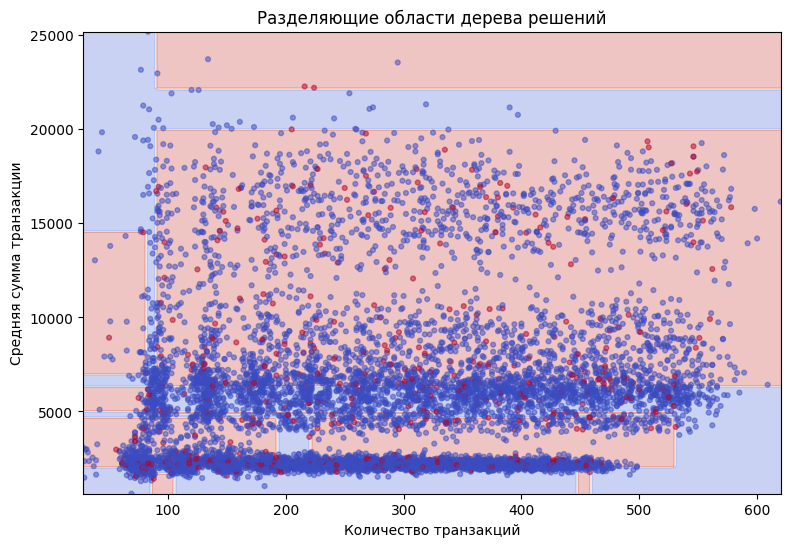

In [13]:
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

features_2d = ["transaction_count", "avg_transaction_amount"]

X_train_2d = X_train[features_2d]

tree_2d = DecisionTreeClassifier(
    max_depth=7,
    min_samples_leaf=5,
    min_samples_split=2,
    criterion="entropy",
    class_weight="balanced",
    random_state=42
)

tree_2d.fit(X_train_2d, y_train)

x_min, x_max = X_train_2d.iloc[:, 0].min(), X_train_2d.iloc[:, 0].max()
y_min, y_max = X_train_2d.iloc[:, 1].min(), X_train_2d.iloc[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)

Z = tree_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_train_2d.iloc[:, 0],
    X_train_2d.iloc[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=12,
    alpha=0.5
)

plt.xlabel("Количество транзакций")
plt.ylabel("Средняя сумма транзакции")
plt.title("Разделяющие области дерева решений")
plt.show()

In [ ]:
'''сравню результаты SVM и
дерева решений по основным метрикам качества, чтобы определить, какая модель лучше справилась с прогнозированием оттока.'''

In [14]:
results = pd.DataFrame({
    "Модель": ["SVM", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_svm, zero_division=0),
        precision_score(y_test, y_pred_tree, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_svm, zero_division=0),
        recall_score(y_test, y_pred_tree, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_svm, zero_division=0),
        f1_score(y_test, y_pred_tree, zero_division=0)
    ]
})

display(results.round(3))

,Модель,Accuracy,Precision,Recall,F1-score
0,SVM,0.526,0.062,0.41,0.107
1,Decision Tree,0.467,0.061,0.46,0.107


In [ ]:
'''
В ходе работы я обучила две модели машинного обучения для прогнозирования оттока клиентов банка:
SVM и Decision Tree. Для обеих моделей я использовала GridSearchCV для подбора гиперпараметров и оценила качество прогнозов на тестовой выборке.

По результатам сравнения Accuracy модели SVM составила 0.526, а Decision Tree — 0.467.
Значение Recall у дерева решений немного выше — 0.46 против 0.41 у SVM. F1-score обеих моделей составил 0.107.
Таким образом, обе модели показали невысокое качество прогнозирования.
Одной из причин может быть сильный дисбаланс классов: клиенты без оттока составляют около 93% данных, а клиенты с оттоком — около 7%.
Я пришла к выводу, что на данном этапе ни одна из моделей не обеспечивает достаточно
точного определения оттока клиентов. Для улучшения результатов можно попробовать балансировку классов,
подбор дополнительных признаков и другие алгоритмы классификации.'''